# Notebook 4 · Question 5: champion optimisation and the one-time test
Runs `src/optimise_q5.py`: Optuna (TPE, seed 42, 60 trials) tunes Logistic Regression on walk-forward cross-validation inside the training
years; the tuned pipeline is locked, refit on 2018–2022 and evaluated **once** on the 2023 test year.

In [1]:
import sys, json, logging, warnings
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", "{:.3f}".format)
RESULTS, FIGS = ROOT / "results", ROOT / "reports" / "figures"
show = lambda name, width=800: display(Image(filename=str(FIGS / name), width=width))

In [2]:
import optimise_q5
optimise_q5.main()

Best CV macro-F1 = 0.8743 with {'C': 0.07415928995129129, 'penalty': 'l1', 'class_weight': 'balanced', 'scaler': 'standard'}



Pre vs post optimisation:
         config  cv_macro_f1_mean  cv_macro_f1_std  val_accuracy  val_macro_f1  val_weighted_f1  val_precision_at_risk  val_recall_at_risk  val_roc_auc  val_pr_auc
Default (Q3/Q4)             0.870            0.023         0.889         0.887            0.889                  0.865               0.874        0.928       0.922
 Tuned (Optuna)             0.874            0.025         0.889         0.887            0.889                  0.865               0.874        0.919       0.910



LOCKED pipeline on test year 2023 (n=240):
              precision    recall  f1-score   support

 not_at_risk      0.908     0.934     0.921       137
     at_risk      0.909     0.874     0.891       103

    accuracy                          0.908       240
   macro avg      0.908     0.904     0.906       240
weighted avg      0.908     0.908     0.908       240

Repeat-last-year rule on 2023: macro-F1=0.9060



Saved locked pipeline to C:\Users\tshin\OneDrive\Desktop\TUT\IDA\IDAproject-Tshinavhe\models\final_pipeline.joblib


## 5.1 Search space, scoring rule and search history

Search: Optuna TPE (seed 42) | 60 trials
Scoring rule: mean macro-F1 over walk-forward folds 2019, 2020, 2021 (training years only)


C               log-uniform 0.001 - 100 (inverse regularisatio...
penalty                                      l2 | l1 | elasticnet
l1_ratio                            0.05 - 0.95 (elasticnet only)
class_weight                                      balanced | none
scaler          standard | robust (robust is less sensitive to...
Name: range, dtype: str

,number,value,params_C,params_class_weight,params_l1_ratio,params_penalty,params_scaler,user_attrs_cv_std
59,59,0.874,0.089,balanced,NaN,l1,standard,0.025
48,48,0.874,0.070,balanced,NaN,l1,standard,0.025
51,51,0.874,0.067,balanced,NaN,l1,standard,0.025
32,32,0.874,0.074,balanced,NaN,l1,standard,0.025
47,47,0.874,0.059,balanced,NaN,l1,standard,0.025


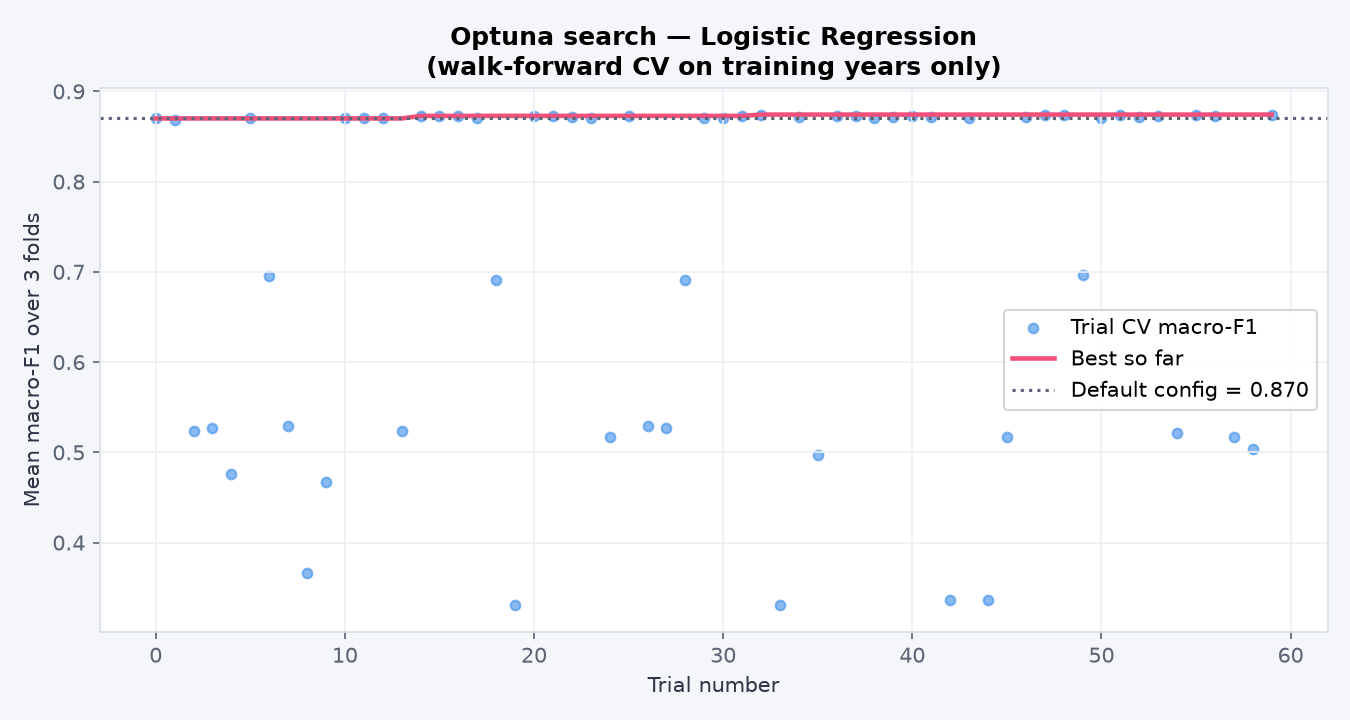

In [3]:
q5 = json.loads((RESULTS / "q5_test_result.json").read_text())
print("Search:", q5["search_method"], "|", q5["n_trials"], "trials")
print("Scoring rule:", q5["scoring_rule"])
display(pd.Series(q5["search_space"], name="range"))
trials = pd.read_csv(RESULTS / "q5_optuna_trials.csv").sort_values("value", ascending=False)
display(trials.head(5))
show("q5_optimisation_history.png", 700)

## 5.2 Before and after optimisation (cross-validation and validation year)

In [4]:
display(pd.DataFrame(q5["pre_post"]).set_index("config"))
print("Chosen hyper-parameters:", q5["best_params"])
import joblib
pipe = joblib.load(ROOT / "models" / "final_pipeline.joblib")
names = pipe.named_steps["preprocess"].get_feature_names_out()
pd.Series(pipe.named_steps["model"].coef_[0], index=names, name="coefficient").sort_values(key=abs, ascending=False)

,cv_macro_f1_mean,cv_macro_f1_std,val_accuracy,val_macro_f1,val_weighted_f1,val_precision_at_risk,val_recall_at_risk,val_roc_auc,val_pr_auc
config,,,,,,,,,
Default (Q3/Q4),0.870,0.023,0.889,0.887,0.889,0.865,0.874,0.928,0.922
Tuned (Optuna),0.874,0.025,0.889,0.887,0.889,0.865,0.874,0.919,0.910


Chosen hyper-parameters: {'C': 0.07415928995129129, 'penalty': 'l1', 'class_weight': 'balanced', 'scaler': 'standard'}


cat__prior_audit_outcome_not_at_risk   -1.710
cat__prior_audit_outcome_at_risk        1.688
num__cash_coverage_ratio               -0.145
num__repairs_maintenance_ratio         -0.115
num__operating_surplus                 -0.100
num__total_revenue                     -0.029
num__total_expenditure                  0.000
num__debtor_days                        0.000
num__collection_rate                    0.000
num__grant_dependency                   0.000
num__irregular_expenditure_ratio        0.000
Name: coefficient, dtype: float64

## 5.3 The locked pipeline on the 2023 test year (used once)

,locked model,repeat-last-year rule
accuracy,0.908,0.908
macro_f1,0.906,0.906
weighted_f1,0.908,0.908
precision_at_risk,0.909,0.909
recall_at_risk,0.874,0.874
roc_auc,0.896,0.904
pr_auc,0.862,0.849


Confusion matrix [[TN, FP], [FN, TP]]: [[128, 9], [13, 90]]


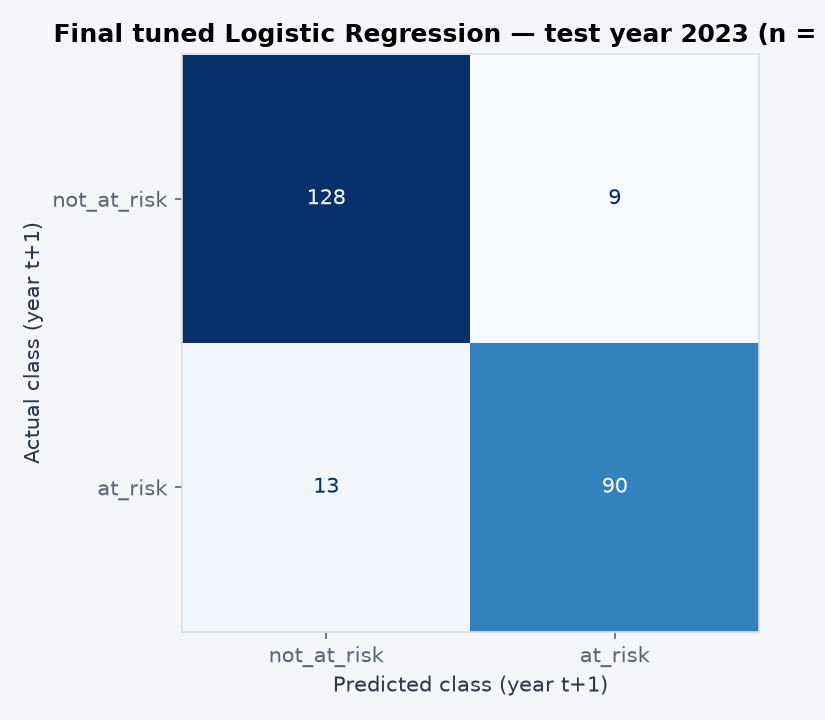

Agreement with the repeat-last-year rule on the test year:

 1.0


In [5]:
display(pd.DataFrame({"locked model": q5["test_metrics"], "repeat-last-year rule": q5["repeat_last_year_test_metrics"]}))
print("Confusion matrix [[TN, FP], [FN, TP]]:", q5["test_confusion"])
show("q5_test_confusion_matrix.png", 420)
pred = pd.read_csv(RESULTS / "q5_test_predictions.csv")
print("Agreement with the repeat-last-year rule on the test year:", (pred.champion_pred == pred.repeat_last_year_pred).mean())